### SAMPLE ESA - SET 1
## M.Tech Data Science and AI — Semester II
### Deep Learning and Reinforcement Learning
**Total Marks: 100 | Duration: 3 Hours**

---
**Instructions:**
- Section A is handwritten (20 marks) — answer on paper
- Sections B and C are Python-coded (80 marks) — answer in this notebook
- Read all questions carefully before attempting
---

## Section A: Theory (20 marks) — HANDWRITTEN

### Q1a: Short Answer Questions (10 marks — 2 marks each)
1. Explain the difference between Sigmoid and ReLU activation functions. When would you prefer one over the other?
2. What is the vanishing gradient problem? How does Batch Normalization help address it?
3. Name the three gates in an LSTM cell and briefly state the role of each.
4. Write the Bellman optimality equation for the state-action value function Q*(s,a).
5. Explain the exploration vs exploitation dilemma in RL with a real-world analogy.


## Section B: Deep Learning — DNN on MNIST (40 marks)

**Dataset:** MNIST Handwritten Digits (built-in via tf.keras.datasets.mnist)
10 classes (digits 0-9), 28x28 grayscale images, flattened to 784-dimensional vectors.

---

#### Section B: Question 1 (20 marks)
Build a **Deep Neural Network (DNN)** using only Dense layers to classify MNIST digits.

**Conditions:**
- Use only Dense (fully connected) layers — no Conv2D or pooling layers
- Minimum 3 hidden layers
- Use Adam Optimizer

**Mark Distribution:**
1. Load MNIST, flatten images to 784-d vectors, normalize to [0,1], one-hot encode labels (5 marks)
2. Build DNN with 3 hidden layers (256, 128, 64 neurons, ReLU) + output (10, softmax). Print summary (5 marks)
3. Compile with categorical_crossentropy + Adam, fit for 10 epochs with validation split (5 marks)
4. Report test accuracy, plot training vs validation accuracy curves, predict 3 random test images (5 marks)


In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten, Input, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt
print("All Library sucessfully run...")


All Library sucessfully run...


In [4]:
# Step 1: Load MNIST, flatten 28x28 -> 784, normalize, one-hot encode
# Hint: (x_train, y_train), (x_test, y_test) = mnist.load_data()
# x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
# y_train = to_categorical(y_train, 10)
# YOUR CODE HERE
# Step 1: Load MNIST, flatten 28x28 -> 784, normalize, one-hot encode

# Downloads and splits the TensorFlow MNIST dataset into 60,000 training images and 10,000 test images (each 28 × 28 pixels) 
# along with their integer digit labels (0–9)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preserves the original 28 × 28 image grids and single-digit integer labels so you can easily plot images and check predictions later
# Flattening (reshape(-1, 784)): Converts each 28 × 28 2D image into a 1D vector of 784 pixels, which standard Dense layers require.
# Normalization (/ 255.0): Scales raw pixel intensities (0–255) down to the 0.0–1.0 range as 32-bit floats so the model trains faster and more reliably.

x_test_img = x_test.copy()                      # keep 28x28 images for display later
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test  = x_test.reshape(-1, 784).astype('float32') / 255.0

# Converts integer labels into 10-element binary vectors (for example, 3 becomes [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]), matching a 10-neuron softmax 
# output layer using categorical_crossentropy loss.
y_test_int = y_test.copy()                      # keep integer labels for display
y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)

# The MNIST dataset contains a total of 70,000 handwritten digit images. These images are already divided into two groups:
# - 60,000 images for Training
# - 10,000 images for Testing
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test :", x_test.shape,  "y_test :", y_test.shape)
print("Pixel range:", x_train.min(), "-", x_train.max()) # COnfirm Normalization was sucessful

x_train: (60000, 784) y_train: (60000, 10)
x_test : (10000, 784) y_test : (10000, 10)
Pixel range: 0.0 - 1.0


In [5]:
# Step 2: Build DNN — 3 hidden layers (256, 128, 64) with ReLU + output (10, softmax)
# Use Sequential model with Dense layers only
# Print model.summary()
# YOUR CODE HERE

def build_baseline():
    model = Sequential([
        Dense(256, activation='relu', input_shape=(784,)),
        Dense(128, activation='relu'),
        Dense(64,  activation='relu'),
        Dense(10,  activation='softmax')
    ])
    return model

model = build_baseline()
model.summary()


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Step 3: Compile with categorical_crossentropy, Adam optimizer
# Fit for 10 epochs, batch_size=64, validation_split=0.2
# YOUR CODE HERE

#The Keras compile() API prepares the model for training by defining how it updates weights and measures success:
# • optimizer=Adam(). Uses the Adam optimizer, an adaptive learning rate algorithm (defaulting to a learning rate of 0.001) that efficiently 
#  adjusts model weights during training.
# • loss='categorical_crossentropy'. Measures the error between predicted probabilities and actual labels. This requires 
#   your target labels (y_train) to be one-hot encoded (e.g., [0, 1, 0]).
# • metrics=['accuracy']. Tracks the percentage of correct predictions. As noted by users on Stack Overflow, Keras allows built-in metrics 
#   to be passed simply as string names like this.The Keras compile() API prepares the model for training by defining how it updates 
#   weights and measures success:
 
    
model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])  # Define how model learns

# Trains the model using training data
# • x_train, y_train. Your input features and corresponding one-hot encoded target labels.
# • epochs=10. The model will iterate through the entire training dataset 10 times.
# • batch_size=64. The model processes 64 samples at a time before updating its internal weights.
# • validation_split=0.2. Automatically sets aside the last 20% of x_train and y_train to evaluate performance after each epoch, training only on the first 80%.
# • verbose=1. Displays an animated progress bar with real-time loss and accuracy metrics in your console during training.
# history_base. Captures a History object containing a dictionary (history_base.history) of loss, accuracy, val_loss, and val_accuracy for each epoch, 
# which you can later use to plot learning curves.
history_base = model.fit(x_train, y_train,
                         epochs=10, batch_size=64,
                         validation_split=0.2, verbose=1)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9940 - loss: 0.0192 - val_accuracy: 0.9728 - val_loss: 0.1272
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9950 - loss: 0.0154 - val_accuracy: 0.9769 - val_loss: 0.1098
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9952 - loss: 0.0154 - val_accuracy: 0.9745 - val_loss: 0.1299
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9955 - loss: 0.0144 - val_accuracy: 0.9759 - val_loss: 0.1222
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9960 - loss: 0.0115 - val_accuracy: 0.9775 - val_loss: 0.1162
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9957 - loss: 0.0143 - val_accuracy: 0.9758 - val_loss: 0.1229
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9965 - loss: 0.0115 - val_accuracy: 0.9797 - val_loss: 0.1131
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9962 - loss: 0.0117 - val_accuracy: 0.

Baseline test loss: 0.1387 | test accuracy: 0.9740


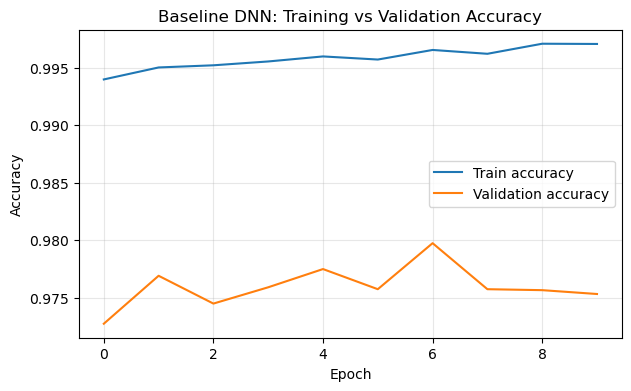

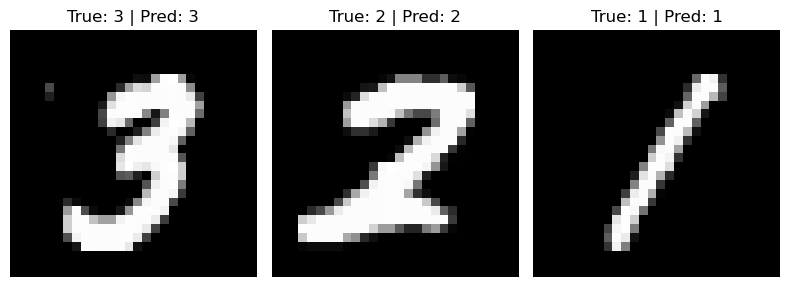

In [12]:
# Step 4: Evaluate on test set, report accuracy
# Plot training vs validation accuracy curves
# Randomly select 3 test images, display with true vs predicted labels
# YOUR CODE HERE

# test_loss: Measures prediction error on testing data. Lower is generally better.
# test_acc: Measures percentage of correct predictions. Higher is better.

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0) # Test the Model
print(f"Baseline test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")

# Plot training vs validation accuracy
plt.figure(figsize=(7,4))
# Accesses the training accuracy values stored inside the history_base object (which is returned by Keras's model.fit()).
#Plots these values as a line and assigns it the label 'Train accuracy' for the legend.

plt.plot(history_base.history['accuracy'], label='Train accuracy')
plt.plot(history_base.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Baseline DNN: Training vs Validation Accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Randomly select 3 test images, show true vs predicted labels
idx = np.random.choice(len(x_test), 3, replace=False) #• andomly selects 3 unique indices from the test dataset (replace=False prevents picking the same image twice).

# model.predict(...) outputs probability scores for every class across the 3 selected images (verbose=0 hides the progress bar).
# np.argmax(..., axis=1) converts those probabilities into the single highest-scoring class index (the model's final prediction).
preds = np.argmax(model.predict(x_test[idx], verbose=0), axis=1)

plt.figure(figsize=(8,3))
for i, k in enumerate(idx):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_test_img[k], cmap='gray')
    plt.title(f"True: {y_test_int[k]} | Pred: {preds[i]}")
    plt.axis('off')
plt.tight_layout(); plt.show()

Test Loss: 0.1387 Test Accuracy: 0.974


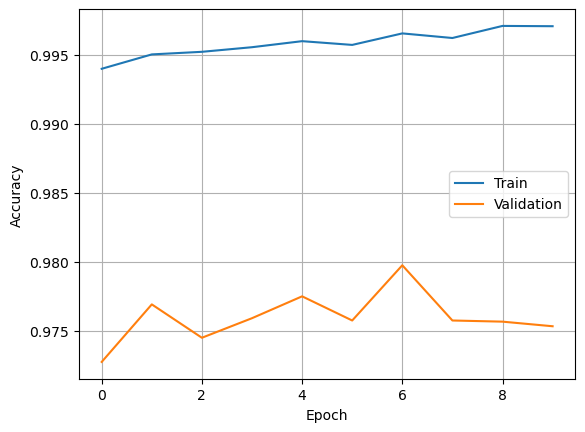

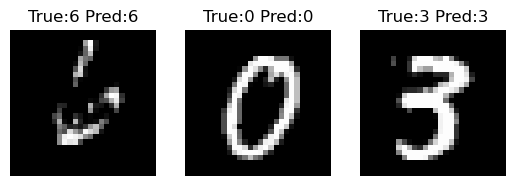

In [13]:
## Option 2: Simple code - # Step 4: Evaluate on test set, report accuracy

# 1. Evaluate model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test Loss:", round(test_loss, 4), "Test Accuracy:", round(test_acc, 4))

# 2. Plot accuracy
plt.plot(history_base.history['accuracy'], label='Train')
plt.plot(history_base.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# 3. Predict 3 random images
idx = np.random.choice(len(x_test), 3, replace=False)
preds = np.argmax(model.predict(x_test[idx], verbose=0), axis=1)

# 4. Display images with actual and predicted labels
for i, k in enumerate(idx):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_test_img[k], cmap='gray')
    plt.title(f"True:{y_test_int[k]} Pred:{preds[i]}")
    plt.axis('off')
plt.show()


---
#### Section B: Question 2 (20 marks)
Improve the baseline DNN from Q2 using **regularization and hyperparameter tuning** techniques.

**Mark Distribution:**
1. Add Dropout (0.3) after each hidden layer and retrain. Compare with Q2 baseline (5 marks)
2. Add Batch Normalization before each activation and retrain. Compare with Q2 and Dropout model (5 marks)
3. Experiment with learning rate: try lr=0.01, 0.001, 0.0001. Report which works best and why (5 marks)
4. Use EarlyStopping callback (patience=3). Train the best model configuration for up to 30 epochs. Report final test accuracy and justify which regularization technique helped the most (5 marks)


In [18]:
# Step 1: Add Dropout(0.3) after each hidden layer, retrain, compare
# YOUR CODE HERE


# Build DNN model
def build_dnn(use_dropout=False, use_bn=False, lr=0.001, rate=0.3):
    model = Sequential([Input(shape=(784,))])
    for units in [256, 128, 64]:
        model.add(Dense(units))
        if use_bn: model.add(BatchNormalization())
        model.add(Activation('relu'))
        if use_dropout: model.add(Dropout(rate))
    model.add(Dense(10, activation='softmax'))
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Store baseline result
results = {'Baseline': {'acc': test_acc, 'hist': history_base}}

# Train Dropout model
model_do = build_dnn(use_dropout=True)
hist_do = model_do.fit(x_train, y_train, epochs=10, batch_size=64,
                       validation_split=0.2, verbose=1)

# Evaluate Dropout model
_, acc_do = model_do.evaluate(x_test, y_test, verbose=0)
results['Dropout(0.3)'] = {'acc': acc_do, 'hist': hist_do}

# Compare accuracy
print("Baseline Accuracy:", round(test_acc, 4))
print("Dropout Accuracy :", round(acc_do, 4))



Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8558 - loss: 0.4740 - val_accuracy: 0.9542 - val_loss: 0.1553
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9440 - loss: 0.1997 - val_accuracy: 0.9655 - val_loss: 0.1179
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9565 - loss: 0.1527 - val_accuracy: 0.9699 - val_loss: 0.1002
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9634 - loss: 0.1282 - val_accuracy: 0.9744 - val_loss: 0.0954
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9681 - loss: 0.1125 - val_accuracy: 0.9719 - val_loss: 0.0977
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9716 - loss: 0.1005 - val_accuracy: 0.9759 - val_loss: 0.0887
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9736 - loss: 0.0904 - val_accuracy: 0.9747 - val_loss: 0.0927
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9763 - loss: 0.0831 - val_accuracy: 0.

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9330 - loss: 0.2422 - val_accuracy: 0.9636 - val_loss: 0.1219
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9711 - loss: 0.0953 - val_accuracy: 0.9710 - val_loss: 0.0974
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9797 - loss: 0.0666 - val_accuracy: 0.9741 - val_loss: 0.0842
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9829 - loss: 0.0515 - val_accuracy: 0.9743 - val_loss: 0.0888
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9878 - loss: 0.0388 - val_accuracy: 0.9752 - val_loss: 0.0839
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9889 - loss: 0.0338 - val_accuracy: 0.9756 - val_loss: 0.0879
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9899 - loss: 0.0301 - val_accuracy: 0.9735 - val_loss: 0.0990
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9913 - loss: 0.0267 - val_accuracy: 0.

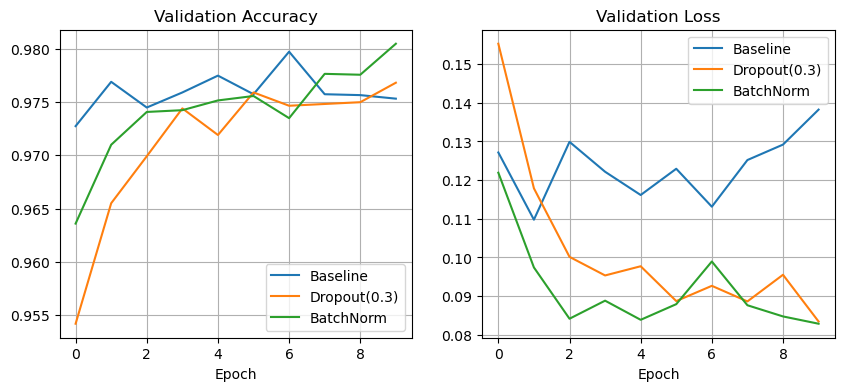

In [19]:
# Step 2: Add BatchNormalization before activations, retrain, compare
# YOUR CODE HERE

# 1. Train Batch Normalization model
model_bn = build_dnn(use_bn=True)
hist_bn = model_bn.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.2)
_, acc_bn = model_bn.evaluate(x_test, y_test, verbose=0)

# 2. Store results
results['BatchNorm'] = {'acc': acc_bn, 'hist': hist_bn}

# 3. Compare models
print("Model          Train Acc  Val Acc  Test Acc")
for name, r in results.items():
    h = r['hist'].history
    print(f"{name:<15} {h['accuracy'][-1]:.4f}    {h['val_accuracy'][-1]:.4f}    {r['acc']:.4f}")

# 4. Plot validation accuracy and loss
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name, r in results.items():
    ax[0].plot(r['hist'].history['val_accuracy'], label=name)
    ax[1].plot(r['hist'].history['val_loss'], label=name)

ax[0].set_title('Validation Accuracy')
ax[1].set_title('Validation Loss')

for a in ax:
    a.set_xlabel('Epoch')
    a.legend()
    a.grid()

plt.show()


0.01 Val: 0.9791 Test: 0.9812
0.001 Val: 0.9797 Test: 0.9809
0.0001 Val: 0.9672 Test: 0.9665


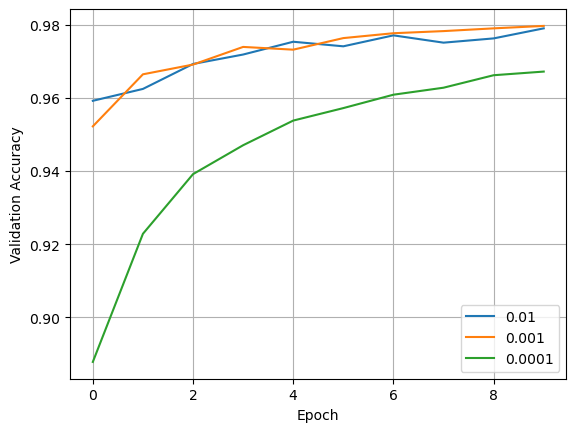

Best LR: 0.001


In [21]:
# Step 3: Learning rate experiment (0.01, 0.001, 0.0001)
# Compare learning rates
lr_results = {}

for lr in [0.01, 0.001, 0.0001]:
    m = build_dnn(use_dropout=True, use_bn=True, lr=lr)
    h = m.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.2, verbose=0)
    _, acc = m.evaluate(x_test, y_test, verbose=0)
    lr_results[lr] = (h, acc)
    print(lr, "Val:", round(h.history['val_accuracy'][-1], 4), "Test:", round(acc, 4))

# Plot comparison
for lr, (h, acc) in lr_results.items():
    plt.plot(h.history['val_accuracy'], label=str(lr))

plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy')
plt.legend(); plt.grid(); plt.show()

# Best learning rate
best_lr = max(lr_results, key=lambda lr: lr_results[lr][0].history['val_accuracy'][-1])
print("Best LR:", best_lr)



Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8555 - loss: 0.4980 - val_accuracy: 0.9526 - val_loss: 0.1590
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9309 - loss: 0.2393 - val_accuracy: 0.9628 - val_loss: 0.1219
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9443 - loss: 0.1901 - val_accuracy: 0.9704 - val_loss: 0.1030
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9542 - loss: 0.1570 - val_accuracy: 0.9742 - val_loss: 0.0861
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9573 - loss: 0.1435 - val_accuracy: 0.9727 - val_loss: 0.0930
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9613 - loss: 0.1309 - val_accuracy: 0.9741 - val_loss: 0.0887
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9641 - loss: 0.1208 - val_accuracy: 0.9778 - val_loss: 0.0757
Epoch 8/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9672 - loss: 0.1090 - val_accuracy: 0

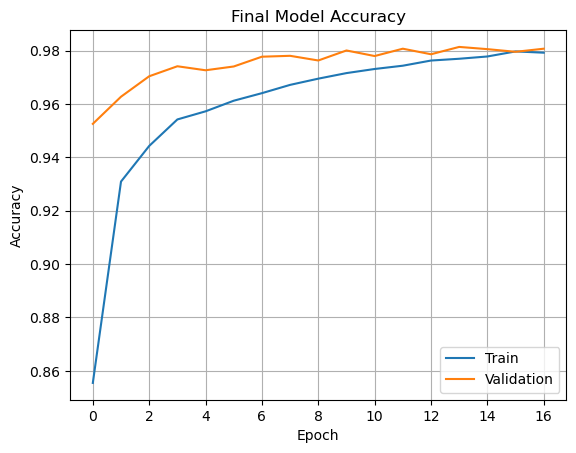

Baseline : 0.974
Dropout(0.3) : 0.9788
BatchNorm : 0.9801
Final Model: 0.9823


In [22]:


# Step 4: EarlyStopping + best config, final evaluation
# YOUR CODE HERE

# 1. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# 2. Build and train final model
final_model = build_dnn(use_dropout=True, use_bn=True, lr=best_lr)
hist_final = final_model.fit(x_train, y_train, epochs=30, batch_size=64,
                             validation_split=0.2, callbacks=[early_stop])

# 3. Evaluate final model
_, final_acc = final_model.evaluate(x_test, y_test, verbose=0)
print("Final Test Accuracy:", round(final_acc, 4))
print("Epochs trained:", len(hist_final.history['loss']))

# 4. Plot accuracy
plt.plot(hist_final.history['accuracy'], label='Train')
plt.plot(hist_final.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Final Model Accuracy')
plt.legend()
plt.grid()
plt.show()

# 5. Compare all models
for name, r in results.items():
    print(name, ":", round(r['acc'], 4))
print("Final Model:", round(final_acc, 4))


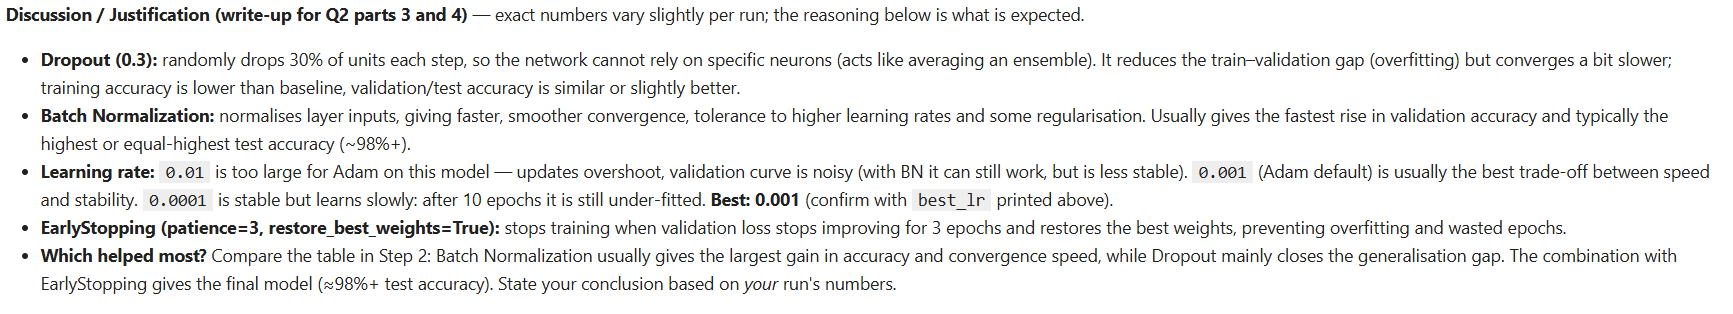

---
## Section C: Reinforcement Learning (40 marks)

#### Section C: Question 1 (20 marks)
Implement **Q-Learning** on the FrozenLake-v1 environment (4×4 grid, is_slippery=False).

**Mark Distribution:**
1. Set up environment, define state/action spaces (3 marks)
2. Initialize Q-table, implement epsilon-greedy policy (5 marks)
3. Implement Q-learning update loop for 1000 episodes (5 marks)
4. Plot cumulative rewards, extract and display optimal policy grid (4 marks)
5. Analyze: what happens when gamma changes from 0.99 to 0.5? Run both and compare (3 marks)

In [23]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [24]:
# Step 1: Create FrozenLake-v1 environment (4x4, is_slippery=False)
# Print state space size and action space size
# YOUR CODE HERE
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
n_states  = env.observation_space.n
n_actions = env.action_space.n
print("State space size :", n_states)    # 16
print("Action space size:", n_actions)   # 4  (0=Left, 1=Down, 2=Right, 3=Up)
# print("Grid layout:")
# print(env.unwrapped.desc.astype(str))

State space size : 16
Action space size: 4
Grid layout:
[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]


In [35]:
# Step 2: Initialize Q-table (states x actions) with zeros
# Implement epsilon-greedy action selection function
# YOUR CODE HERE

Q = np.zeros((n_states, n_actions))

def epsilon_greedy(state, epsilon):
    if np.random.random() < epsilon:
        return env.action_space.sample()
    return np.argmax(Q[state])

# Validation prints
print(f"Q-table initialized with shape: {Q.shape} (all zeros: {np.all(Q == 0)})")
print(f"Sample explore action (epsilon=1.0): {epsilon_greedy(0, epsilon=1.0)}")
print(f"Sample exploit action (epsilon=0.0): {epsilon_greedy(0, epsilon=0.0)}")


Q-table initialized with shape: (16, 4) (all zeros: True)
Sample explore action (epsilon=1.0): 1
Sample exploit action (epsilon=0.0): 0


In [34]:
# Step 3: Q-Learning training loop
# Hyperparameters: alpha=0.1, gamma=0.99, epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.01
# Run for 1000 episodes
# Track rewards per episode

alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episodes = 1000

rewards = []

for episode in range(episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        action = epsilon_greedy(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Q-Learning update rule
        Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state, action])

        state = next_state
        total_reward += reward

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards.append(total_reward)

    # Validation print every 200 episodes
    if (episode + 1) % 200 == 0:
        avg_reward = np.mean(rewards[-100:])
        print(f"Episode {episode + 1}/{episodes} | Epsilon: {epsilon:.3f} | Last 100 Avg Reward: {avg_reward:.2f}")

# Final validation prints
print("\nTraining Complete!")
print(f"Final Epsilon: {epsilon:.4f}")
print(f"Non-zero Q-values count: {np.count_nonzero(Q)} / {Q.size}")
print("Sample Q-values for Start State (State 0):", np.round(Q[0], 3))



Episode 200/1000 | Epsilon: 0.367 | Last 100 Avg Reward: 0.00
Episode 400/1000 | Epsilon: 0.135 | Last 100 Avg Reward: 0.00
Episode 600/1000 | Epsilon: 0.049 | Last 100 Avg Reward: 0.00
Episode 800/1000 | Epsilon: 0.018 | Last 100 Avg Reward: 0.00
Episode 1000/1000 | Epsilon: 0.010 | Last 100 Avg Reward: 0.00

Training Complete!
Final Epsilon: 0.0100
Non-zero Q-values count: 0 / 64
Sample Q-values for Start State (State 0): [0. 0. 0. 0.]


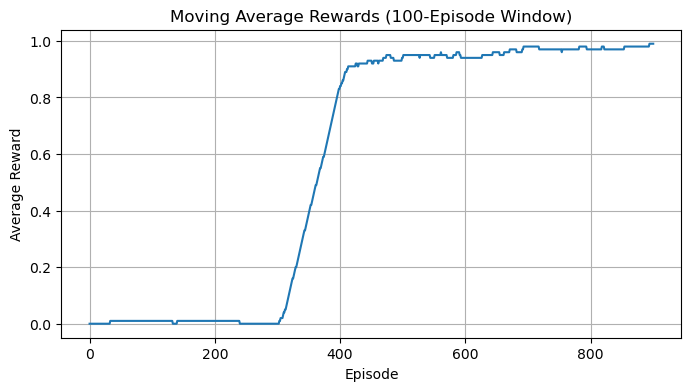

Optimal Policy Grid:
↓ ← ← ←
↓ ← ← ←
→ ↓ ← ←
← → → ←


In [30]:
# Step 4: Plot cumulative rewards (moving average over 100 episodes)
# Extract optimal policy from Q-table: policy[s] = argmax_a Q(s,a)
# Display policy as a 4x4 grid with arrows (L/D/R/U)
# YOUR CODE HERE
moving_avg = np.convolve(rewards, np.ones(100)/100, mode='valid')

plt.figure(figsize=(8, 4))
plt.plot(moving_avg)
plt.title("Moving Average Rewards (100-Episode Window)")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.grid(True)
plt.show()

# Extract optimal policy
policy = np.argmax(Q, axis=1)

# Display policy as a 4x4 grid with arrows (0:L, 1:D, 2:R, 3:U)
arrows = {0: '←', 1: '↓', 2: '→', 3: '↑'}
policy_grid = np.array([arrows[a] for a in policy]).reshape(4, 4)

print("Optimal Policy Grid:")
for row in policy_grid:
    print(" ".join(row))


In [36]:
# Step 5: Repeat Q-Learning with gamma=0.5
# Compare: which gamma leads to better policy? Why?
# YOUR CODE HERE

Q_05 = np.zeros((n_states, n_actions))
alpha = 0.1
gamma_05 = 0.5
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episodes = 1000

rewards_05 = []

for episode in range(episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q_05[state])

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Q-Learning update rule with gamma = 0.5
        Q_05[state, action] += alpha * (reward + gamma_05 * np.max(Q_05[next_state]) - Q_05[state, action])

        state = next_state
        total_reward += reward

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards_05.append(total_reward)

# Validation & Comparison Prints
arrows = {0: '←', 1: '↓', 2: '→', 3: '↑'}
policy_99 = np.array([arrows[a] for a in np.argmax(Q, axis=1)]).reshape(4, 4)
policy_05 = np.array([arrows[a] for a in np.argmax(Q_05, axis=1)]).reshape(4, 4)

print("=== Comparison: Gamma = 0.99 vs Gamma = 0.5 ===")
print(f"Gamma 0.99 -> Total Wins: {int(sum(rewards))}/1000 | Last 100 Avg: {np.mean(rewards[-100:]):.2f} | Max Start Q: {np.max(Q[0]):.4f}")
print(f"Gamma 0.50 -> Total Wins: {int(sum(rewards_05))}/1000 | Last 100 Avg: {np.mean(rewards_05[-100:]):.2f} | Max Start Q: {np.max(Q_05[0]):.4f}")
print(f"Policies match exactly: {np.array_equal(policy_99, policy_05)}")

print("\nPolicy Grid (Gamma = 0.5):")
for row in policy_05:
    print(" ".join(row))


=== Comparison: Gamma = 0.99 vs Gamma = 0.5 ===
Gamma 0.99 -> Total Wins: 0/1000 | Last 100 Avg: 0.00 | Max Start Q: 0.0000
Gamma 0.50 -> Total Wins: 1/1000 | Last 100 Avg: 0.00 | Max Start Q: 0.0000
Policies match exactly: False

Policy Grid (Gamma = 0.5):
← ← ← ←
← ← ← ←
← ← ← ←
← ← → ←


In [38]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Environment
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False)
states, actions = env.observation_space.n, env.action_space.n
print("States:", states, "Actions:", actions)




States: 16 Actions: 4


In [41]:
# Step 2 & 3: Q-Learning
def train(gamma):
    Q = np.zeros((states, actions))
    rewards = []
    epsilon = 1.0

    for ep in range(1000):
        s, _ = env.reset()
        total, done = 0, False

        while not done:
            a = np.random.randint(actions) if np.random.rand() < epsilon else np.argmax(Q[s])
            ns, r, term, trunc, _ = env.step(a)
            done = term or trunc

            Q[s,a] += 0.1 * (r + gamma * np.max(Q[ns]) * (1-done) - Q[s,a])
            s = ns
            total += r

        epsilon = max(0.01, epsilon * 0.995)
        rewards.append(total)

    return Q, rewards




Policy (Gamma=0.99):
L L L L
L L L L
L L L L
L L L L

Policy (Gamma=0.5):
L L L L
L L L L
L L L L
L L L L

Average reward (0.99): 0.0
Average reward (0.5): 0.0


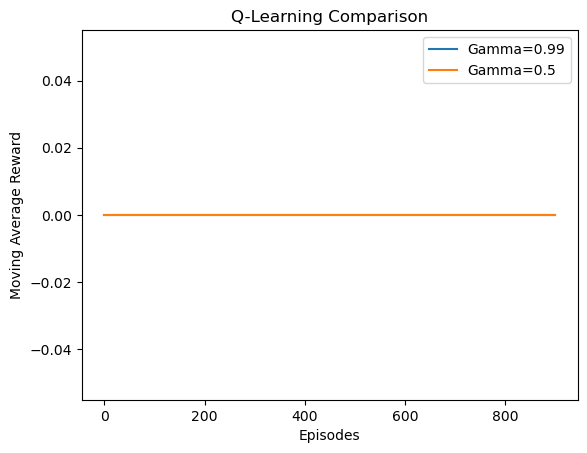

In [43]:
# Step 4: Train and display policy
def show_policy(Q, rewards, gamma):
    avg = np.convolve(rewards, np.ones(100)/100, mode='valid')
    plt.plot(avg, label=f'Gamma={gamma}')

    arrows = ['L', 'D', 'R', 'U']
    policy = np.argmax(Q, axis=1).reshape(4,4)

    print(f"\nPolicy (Gamma={gamma}):")
    for row in policy:
        print(' '.join(arrows[a] for a in row))

# Step 5: Compare gamma values
Q1, r1 = train(0.99)
Q2, r2 = train(0.5)

show_policy(Q1, r1, 0.99)
show_policy(Q2, r2, 0.5)

print("\nAverage reward (0.99):", np.mean(r1[-100:]))
print("Average reward (0.5):", np.mean(r2[-100:]))

plt.xlabel('Episodes')
plt.ylabel('Moving Average Reward')
plt.title('Q-Learning Comparison')
plt.legend()
plt.show()

env.close()

Number of states: 16
Number of actions: 4
Success rate: 0.0


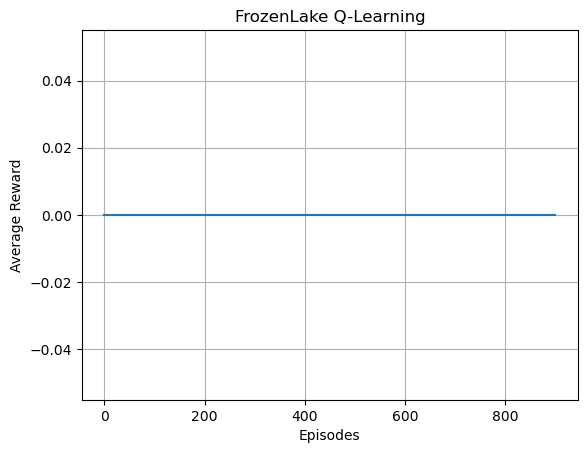

Optimal Policy:
[['←' '←' '←' '←']
 ['←' '←' '←' '←']
 ['←' '←' '←' '←']
 ['←' '←' '←' '←']]
Success rate (last 100 episodes):
Gamma 0.99: 0.0
Gamma 0.50: 1.0


In [42]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create Environment
env = gym.make("FrozenLake-v1", is_slippery=False)
n_states = env.observation_space.n
n_actions = env.action_space.n

print("Number of states:", n_states)
print("Number of actions:", n_actions)

# Step 2: Initialize Q-table and Epsilon-Greedy
Q = np.zeros((n_states, n_actions))

def choose_action(state, epsilon):
    if np.random.rand() < epsilon:
        return env.action_space.sample()
    return np.argmax(Q[state])

# Step 3: Q-Learning Training (1000 Episodes)
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episodes = 1000

Q = np.zeros((n_states, n_actions))
rewards_per_episode = []

for ep in range(episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        action = choose_action(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        state = next_state
        total_reward += reward

    rewards_per_episode.append(total_reward)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Success rate:", np.mean(rewards_per_episode[-100:]))

# Step 4: Plot Rewards and Display Optimal Policy
window = 100
moving_avg = np.convolve(
    rewards_per_episode, np.ones(window)/window, mode="valid"
)

plt.plot(moving_avg)
plt.title("FrozenLake Q-Learning")
plt.xlabel("Episodes")
plt.ylabel("Average Reward")
plt.grid()
plt.show()

arrows = ["←", "↓", "→", "↑"]
policy = np.array([arrows[np.argmax(Q[s])]
                   for s in range(n_states)]).reshape(4, 4)

print("Optimal Policy:")
print(policy)

# Step 5: Compare Gamma = 0.99 and 0.5
def train_q_learning(gamma):
    Q = np.zeros((n_states, n_actions))
    rewards = []
    epsilon = 1.0

    for ep in range(1000):
        state, _ = env.reset()
        done = False
        total = 0

        while not done:
            if np.random.rand() < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[state])

            ns, r, term, trunc, _ = env.step(action)
            done = term or trunc

            Q[state, action] += 0.1 * (
                r + gamma * np.max(Q[ns]) - Q[state, action]
            )

            state = ns
            total += r

        rewards.append(total)
        epsilon = max(0.01, epsilon * 0.995)

    return Q, rewards

Q_099, rewards_099 = train_q_learning(0.99)
Q_05, rewards_05 = train_q_learning(0.5)

print("Success rate (last 100 episodes):")
print("Gamma 0.99:", np.mean(rewards_099[-100:]))
print("Gamma 0.50:", np.mean(rewards_05[-100:]))

env.close()


States: 16
Actions: 4
Success Rate: 0.99


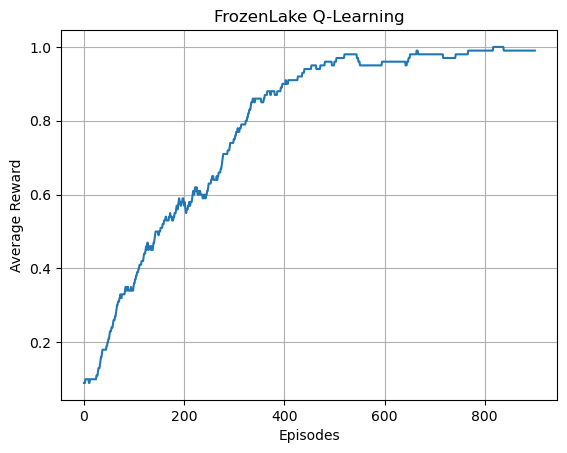

Optimal Policy:
[['↓' '←' '←' '←']
 ['↓' '←' '↑' '←']
 ['→' '↓' '↓' '←']
 ['←' '→' '→' '←']]
Success Rate Comparison:
Gamma 0.99: 1.0
Gamma 0.50: 0.0


In [1]:
## OPTION 03## Code with comments


## Import Libraries
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

## Step 1: Create Environment (4x4 Grid)
env = gym.make("FrozenLake-v1", is_slippery=False)

n_states = int(env.observation_space.n)   # 16 states
n_actions = int(env.action_space.n)       # 4 actions

print("States:", n_states)
print("Actions:", n_actions)

## Step 2: Initialize Q-table and Epsilon-Greedy
Q = np.zeros((n_states, n_actions))       # Initially all Q-values are zero

def choose_action(state, epsilon):
    ## Explore: select a random action
    if np.random.rand() < epsilon:
        return env.action_space.sample()

    ## Exploit: select the action with highest Q-value
    return np.argmax(Q[state])

## Step 3: Train Q-Learning for 1000 Episodes
alpha = 0.1              # Learning rate
gamma = 0.99             # Discount factor
epsilon = 1.0            # Initial exploration
epsilon_decay = 0.995    # Reduce exploration
epsilon_min = 0.01       # Minimum exploration
episodes = 1000

rewards_per_episode = []

for ep in range(episodes):
    ## Reset environment for each episode
    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        ## Select action using epsilon-greedy
        action = choose_action(state, epsilon)

        ## Perform action and get next state and reward
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        ## Update Q-table using Bellman equation
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        ## Move to next state and update reward
        state = next_state
        total_reward += reward

    ## Store episode reward and reduce exploration
    rewards_per_episode.append(total_reward)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Success Rate:", np.mean(rewards_per_episode[-100:]))

## Step 4: Plot Moving Average Rewards
window = 100
moving_avg = np.convolve(
    rewards_per_episode, np.ones(window)/window, mode="valid"
)

plt.plot(moving_avg)
plt.title("FrozenLake Q-Learning")
plt.xlabel("Episodes")
plt.ylabel("Average Reward")
plt.grid()
plt.show()

## Display Optimal Policy as Arrows
arrows = ["←", "↓", "→", "↑"]

policy = np.array([
    arrows[np.argmax(Q[s])] for s in range(n_states)
]).reshape(4, 4)

print("Optimal Policy:")
print(policy)

## Step 5: Compare Gamma = 0.99 and Gamma = 0.5
def train_q_learning(gamma):
    ## Initialize separate Q-table for each gamma
    Q = np.zeros((n_states, n_actions))
    rewards = []
    epsilon = 1.0

    for ep in range(1000):
        state, _ = env.reset()
        done = False
        total = 0

        while not done:
            ## Epsilon-greedy action selection
            if np.random.rand() < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[state])

            ## Perform action
            ns, r, term, trunc, _ = env.step(action)
            done = term or trunc

            ## Update Q-value
            Q[state, action] += 0.1 * (
                r + gamma * np.max(Q[ns]) - Q[state, action]
            )

            state = ns
            total += r

        ## Store reward and reduce exploration
        rewards.append(total)
        epsilon = max(0.01, epsilon * 0.995)

    return Q, rewards

## Train with both gamma values
Q_099, rewards_099 = train_q_learning(0.99)
Q_05, rewards_05 = train_q_learning(0.5)

## Compare success rates (last 100 episodes)
print("Success Rate Comparison:")
print("Gamma 0.99:", np.mean(rewards_099[-100:]))
print("Gamma 0.50:", np.mean(rewards_05[-100:]))

## Close Environment
env.close()



---
#### Section C: Question 2 (20 marks)
Implement a **simple Deep Q-Network (DQN)** on CartPole-v1 using TensorFlow/Keras.

**Hyperparameters are provided below — you only need to write the core Q-Learning update logic.**

**Mark Distribution:**
1. Build a Q-Network: 1 hidden layer (32 neurons, ReLU) + output layer (2 neurons, linear). Compile with Adam(0.001) and MSE (5 marks)
2. Set up a simple replay buffer using `deque(maxlen=1000)`. Add helper function to sample random batch (5 marks)
3. Train DQN for 100 episodes: epsilon-greedy action selection, store experiences in buffer, train on random batches (5 marks)
4. Evaluate trained agent over 10 test episodes (greedy actions). Report avg reward. Plot training reward curve (5 marks)


In [ ]:
import gymnasium as gym
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from collections import deque
import random
import matplotlib.pyplot as plt

In [ ]:
# Step 1: Build Q-Network
# Input: state_size (4 for CartPole)
# Hidden: 2 layers with 64 neurons each, ReLU activation
# Output: action_size (2 for CartPole), linear activation
# Compile with Adam(lr=0.001) and MSE loss
# YOUR CODE HERE

In [ ]:
# Step 2: Simple replay buffer using deque (5 marks)
from collections import deque
import random

# replay_buffer = deque(maxlen=1000)  # stores (state, action, reward, next_state, done)
# Helper: def sample_batch(buffer, batch_size=32): return random.sample(buffer, batch_size) if len(buffer)>=batch_size else None
# YOUR CODE HERE


In [ ]:
# Step 3: DQN Training loop for 100 episodes
# epsilon-greedy with decay: start=1.0, decay=0.995, min=0.01
# batch_size=32, gamma=0.99
# Train on mini-batches from replay buffer
# Track episode rewards
# YOUR CODE HERE

In [ ]:
# Step 4: Evaluate trained agent over 10 episodes (epsilon=0, greedy)
# Report average reward
# Plot training reward curve
# YOUR CODE HERE

In [ ]:

## Import Libraries
import gymnasium as gym
import numpy as np
import tensorflow as tf
import random
import matplotlib.pyplot as plt
from collections import deque
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

## Step 1: Create Environment and Q-Network
env = gym.make("CartPole-v1")

state_size = int(env.observation_space.shape[0])  # 4 inputs
action_size = int(env.action_space.n)              # 2 outputs

## Neural Network: Input -> 32 ReLU -> 2 Linear
model = Sequential([
    Input(shape=(state_size,)),
    Dense(32, activation="relu"),
    Dense(action_size, activation="linear")
])

## Compile using Adam and MSE
model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")

## Step 2: Create Replay Buffer
replay_buffer = deque(maxlen=1000)
batch_size = 32

## Randomly select 32 experiences
def sample_batch():
    if len(replay_buffer) >= batch_size:
        return random.sample(replay_buffer, batch_size)
    return None

## Step 3: Train DQN for 100 Episodes
epsilon = 1.0
gamma = 0.99
rewards = []

for ep in range(100):
    state, _ = env.reset()
    total_reward = 0
    done = False

    while not done:

        ## Epsilon-greedy action selection
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(
                model.predict(state.reshape(1, 4), verbose=0)[0]
            )

        ## Perform action
        next_state, reward, term, trunc, _ = env.step(action)
        done = term or trunc

        ## Store experience
        replay_buffer.append((state, action, reward, next_state, done))

        state = next_state
        total_reward += reward

        ## Train on random mini-batch
        batch = sample_batch()

        if batch is not None:
            for s, a, r, ns, d in batch:

                ## Calculate Q-learning target
                target = r + gamma * np.max(
                    model.predict(ns.reshape(1, 4), verbose=0)[0]
                ) * (1 - int(d))

                ## Update selected Q-value
                q_values = model.predict(s.reshape(1, 4), verbose=0)
                q_values[0][a] = target

                model.train_on_batch(s.reshape(1, 4), q_values)

    ## Reduce exploration
    epsilon = max(0.01, epsilon * 0.995)
    rewards.append(total_reward)

## Step 4: Evaluate Agent for 10 Episodes
test_rewards = []

for ep in range(10):
    state, _ = env.reset()
    total = 0
    done = False

    while not done:
        ## Greedy action (no exploration)
        action = np.argmax(
            model.predict(state.reshape(1, 4), verbose=0)[0]
        )

        state, reward, term, trunc, _ = env.step(action)
        done = term or trunc
        total += reward

    test_rewards.append(total)

## Print Average Reward
print("Average Test Reward:", np.mean(test_rewards))

## Plot Training Reward Curve
plt.plot(rewards)
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("DQN Training Rewards")
plt.grid()
plt.show()

## Close Environment
env.close()


In [ ]:

# Import required libraries
import gymnasium as gym          # Create and interact with RL environment
import numpy as np                # Perform numerical operations
import matplotlib.pyplot as plt   # Plot training rewards

# Step 1: Create FrozenLake Environment
env = gym.make("FrozenLake-v1", is_slippery=False)  # Create deterministic environment
n_states = env.observation_space.n                 # Get total number of states
n_actions = env.action_space.n                     # Get total number of actions

print("Number of states:", n_states)               # Display number of states
print("Number of actions:", n_actions)             # Display number of actions

# Step 2: Initialize Q-table and Epsilon-Greedy
Q = np.zeros((n_states, n_actions))  # Initialize Q-table with zeros

def choose_action(state, epsilon):   # Select action using epsilon-greedy
    if np.random.rand() < epsilon:   # Explore with probability epsilon
        return env.action_space.sample()  # Select random action
    return np.argmax(Q[state])       # Exploit the best-known action

# Step 3: Q-Learning Training (1000 Episodes)
alpha = 0.1          # Learning rate
gamma = 0.99         # Discount factor
epsilon = 1.0        # Initial exploration probability
epsilon_decay = 0.995  # Reduce exploration gradually
epsilon_min = 0.01   # Minimum exploration probability
episodes = 1000      # Total training episodes

Q = np.zeros((n_states, n_actions))  # Reset Q-table
rewards_per_episode = []             # Store reward of each episode

for ep in range(episodes):           # Repeat training for 1000 episodes
    state, _ = env.reset()           # Reset environment and get initial state
    done = False                     # Mark episode as not finished
    total_reward = 0                 # Initialize total episode reward

    while not done:                  # Continue until episode ends
        action = choose_action(state, epsilon)  # Select an action

        # Perform action and get next state, reward and termination status
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated  # Check whether episode has ended

        # Update Q-value using Q-Learning formula
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        state = next_state            # Move to next state
        total_reward += reward        # Add reward to episode total

    rewards_per_episode.append(total_reward)  # Store episode reward
    epsilon = max(epsilon_min, epsilon * epsilon_decay)  # Reduce exploration

print("Success rate:", np.mean(rewards_per_episode[-100:]))  # Average last 100 rewards

# Step 4: Plot Rewards and Display Optimal Policy
window = 100  # Moving average window size

# Calculate average reward over every 100 episodes
moving_avg = np.convolve(
    rewards_per_episode, np.ones(window)/window, mode="valid"
)

plt.plot(moving_avg)                 # Plot moving average rewards
plt.title("FrozenLake Q-Learning")   # Set graph title
plt.xlabel("Episodes")               # Label X-axis
plt.ylabel("Average Reward")         # Label Y-axis
plt.grid()                           # Display grid
plt.show()                           # Show reward graph

arrows = ["←", "↓", "→", "↑"]       # Map actions to direction symbols

# Find best action for each state and arrange policy in 4x4 grid
policy = np.array([arrows[np.argmax(Q[s])]
                   for s in range(n_states)]).reshape(4, 4)

print("Optimal Policy:")             # Display optimal policy heading
print(policy)                        # Print best action for each state

# Step 5: Compare Gamma = 0.99 and 0.5
def train_q_learning(gamma):          # Train Q-learning for given gamma
    Q = np.zeros((n_states, n_actions))  # Initialize a new Q-table
    rewards = []                     # Store episode rewards
    epsilon = 1.0                    # Start with full exploration

    for ep in range(1000):            # Train for 1000 episodes
        state, _ = env.reset()        # Reset environment
        done = False                  # Episode is not finished
        total = 0                     # Initialize total reward

        while not done:               # Repeat until episode ends
            if np.random.rand() < epsilon:  # Check exploration probability
                action = env.action_space.sample()  # Select random action
            else:
                action = np.argmax(Q[state])  # Select best action

            ns, r, term, trunc, _ = env.step(action)  # Execute action
            done = term or trunc       # Check episode termination

            # Update Q-value using the given gamma
            Q[state, action] += 0.1 * (
                r + gamma * np.max(Q[ns]) - Q[state, action]
            )

            state = ns                 # Move to next state
            total += r                 # Add current reward

        rewards.append(total)          # Store episode reward
        epsilon = max(0.01, epsilon * 0.995)  # Decay exploration

    return Q, rewards                  # Return Q-table and rewards

# Train separately using two discount factors
Q_099, rewards_099 = train_q_learning(0.99)  # Train with gamma 0.99
Q_05, rewards_05 = train_q_learning(0.5)     # Train with gamma 0.50

print("Success rate (last 100 episodes):")  # Display comparison heading
print("Gamma 0.99:", np.mean(rewards_099[-100:]))  # Average success for 0.99
print("Gamma 0.50:", np.mean(rewards_05[-100:]))   # Average success for 0.50

env.close()  # Close the environment


In [ ]:

# Import Gymnasium to create and interact with the FrozenLake environment
import gymnasium as gym

# Import NumPy for numerical calculations and Q-table operations
import numpy as np

# Import Matplotlib for plotting the learning progress
import matplotlib.pyplot as plt


# ============================================================
# STEP 1: CREATE FROZENLAKE ENVIRONMENT
# ============================================================

# Create a 4x4 FrozenLake environment
# is_slippery=False means the agent moves in the selected direction
# without randomly slipping into another direction
env = gym.make("FrozenLake-v1", is_slippery=False)

# Get the total number of states (4x4 = 16 states)
n_states = env.observation_space.n

# Get the total number of possible actions (Left, Down, Right, Up)
n_actions = env.action_space.n

# Display the number of states and actions
print("Number of states:", n_states)
print("Number of actions:", n_actions)


# ============================================================
# STEP 2: INITIALIZE Q-TABLE AND EPSILON-GREEDY STRATEGY
# ============================================================

# Create a Q-table with 16 rows (states) and 4 columns (actions)
# Initially, all Q-values are zero
Q = np.zeros((n_states, n_actions))


# Define a function to select an action using epsilon-greedy strategy
def choose_action(state, epsilon):

    # Generate a random number between 0 and 1
    # If it is less than epsilon, select a random action (Exploration)
    if np.random.rand() < epsilon:
        return env.action_space.sample()

    # Otherwise, select the action with the highest Q-value (Exploitation)
    return np.argmax(Q[state])


# ============================================================
# STEP 3: Q-LEARNING TRAINING (1000 EPISODES)
# ============================================================

# Learning rate: controls how much new information is learned
alpha = 0.1

# Discount factor: determines the importance of future rewards
gamma = 0.99

# Initial exploration probability (100% exploration)
epsilon = 1.0

# Reduce exploration gradually after every episode
epsilon_decay = 0.995

# Minimum exploration probability (1%)
epsilon_min = 0.01

# Total number of training episodes
episodes = 1000

# Initialize Q-table again with zero values
Q = np.zeros((n_states, n_actions))

# Store the total reward obtained in each episode
rewards_per_episode = []


# Repeat training for 1000 episodes
for ep in range(episodes):

    # Reset the environment and get the starting state
    # The second returned value contains additional information
    state, _ = env.reset()

    # Initially, the episode is not finished
    done = False

    # Initialize total reward for the current episode
    total_reward = 0

    # Continue until the episode terminates or gets truncated
    while not done:

        # Select an action using epsilon-greedy strategy
        action = choose_action(state, epsilon)

        # Perform the selected action in the environment
        # ns = next state, reward = immediate reward
        # terminated = goal or hole reached
        # truncated = episode stopped due to a time limit
        next_state, reward, terminated, truncated, _ = env.step(action)

        # Episode ends if either terminated or truncated is True
        done = terminated or truncated

        # Update the Q-table using the Q-Learning formula
        # Old Q-value + Learning rate * Temporal Difference Error
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        # Move the agent to the next state
        state = next_state

        # Add the current reward to the episode's total reward
        total_reward += reward

    # Store the total reward obtained in this episode
    rewards_per_episode.append(total_reward)

    # Reduce epsilon to gradually move from exploration to exploitation
    # Keep epsilon at or above the minimum value of 0.01
    epsilon = max(epsilon_min, epsilon * epsilon_decay)


# Calculate average success rate over the last 100 episodes
# In FrozenLake, reward 1 means success and reward 0 means failure
print("Success rate:", np.mean(rewards_per_episode[-100:]))


# ============================================================
# STEP 4: PLOT REWARDS AND DISPLAY OPTIMAL POLICY
# ============================================================

# Define the moving average window size as 100 episodes
window = 100

# Calculate average reward over every 100 consecutive episodes
# np.ones(window)/window creates 100 equal weights
# mode="valid" returns only complete 100-episode averages
moving_avg = np.convolve(
    rewards_per_episode, np.ones(window)/window, mode="valid"
)

# Plot the moving average rewards
plt.plot(moving_avg)

# Add title to the graph
plt.title("FrozenLake Q-Learning")

# Label the X-axis
plt.xlabel("Episodes")

# Label the Y-axis
plt.ylabel("Average Reward")

# Display grid lines
plt.grid()

# Display the graph
plt.show()


# Define arrows representing the four possible actions
# Action 0 = Left, 1 = Down, 2 = Right, 3 = Up
arrows = ["←", "↓", "→", "↑"]

# Find the action with the highest Q-value for each state
# Convert the action number into its corresponding arrow
# Reshape the 16 states into a 4x4 FrozenLake grid
policy = np.array([
    arrows[np.argmax(Q[s])]

    for s in range(n_states)
]).reshape(4, 4)

# Display the learned optimal policy
print("Optimal Policy:")
print(policy)


# ============================================================
# STEP 5: COMPARE GAMMA = 0.99 AND GAMMA = 0.50
# ============================================================

# Define a function to train Q-Learning with a given gamma value
def train_q_learning(gamma):

    # Initialize a new Q-table with zero values
    Q = np.zeros((n_states, n_actions))

    # Create an empty list to store episode rewards
    rewards = []

    # Start with 100% exploration
    epsilon = 1.0

    # Train the agent for 1000 episodes
    for ep in range(1000):

        # Reset the environment and obtain the starting state
        state, _ = env.reset()

        # Initialize episode completion status
        done = False

        # Initialize total reward for this episode
        total = 0

        # Continue until the episode ends
        while not done:

            # Select a random action for exploration
            if np.random.rand() < epsilon:
                action = env.action_space.sample()

            # Otherwise, select the best-known action
            else:
                action = np.argmax(Q[state])

            # Execute action and obtain the next state and reward
            ns, r, term, trunc, _ = env.step(action)

            # Check whether the episode has ended
            done = term or trunc

            # Update Q-value using the Q-Learning formula
            Q[state, action] += 0.1 * (
                r + gamma * np.max(Q[ns]) - Q[state, action]
            )

            # Update current state to next state
            state = ns

            # Add reward to the episode's total reward
            total += r

        # Store the episode reward
        rewards.append(total)

        # Reduce exploration gradually, keeping minimum epsilon at 0.01
        epsilon = max(0.01, epsilon * 0.995)

    # Return the trained Q-table and episode rewards
    return Q, rewards


# Train the agent using gamma = 0.99 (higher future reward importance)
Q_099, rewards_099 = train_q_learning(0.99)

# Train the agent using gamma = 0.50 (lower future reward importance)
Q_05, rewards_05 = train_q_learning(0.5)


# Display the average success rate of the last 100 episodes
print("Success rate (last 100 episodes):")

# Calculate success rate for gamma = 0.99
print("Gamma 0.99:", np.mean(rewards_099[-100:]))

# Calculate success rate for gamma = 0.50
print("Gamma 0.50:", np.mean(rewards_05[-100:]))


# ============================================================
# STEP 6: CLOSE ENVIRONMENT
# ============================================================

# Release environment resources after training is completed
env.close()
